# 03_univariate — Analisis Univariat (M3)
**Tim:** Yusuf · **Data:** `genshin_impact_clean.csv` (keluaran `01_quality.ipynb`) · **EDA (KMTI21133)**

Notebook ini melihat **satu variabel sendiri-sendiri**: bentuk sebaran, ukuran pusat, outlier, lalu tafsirannya. Hubungan antarvariabel ada di `04_multivariate.ipynb`.

## Data yang dipakai, dan konsekuensinya
`genshin_impact_clean.csv` adalah hasil penanganan data pribadi di `01_quality.ipynb`: 9 kolom dibuang, `name` di-hash, `release_date` digeneralisasi menjadi `kelompok_umur_rilis`, dan kolom `gender` diturunkan dari `3D-model`. Akibatnya:

| Tidak tersedia lagi | Pengganti di notebook ini |
|---|---|
| `release_date`, `days_since_release`, `months_since_release` | `kelompok_umur_rilis` (5 kelompok **ordinal**), diberi kode 1–5 pada `usia_rilis_kode` |
| `lvl_90_HP`, `lvl_90_ATK`, `lvl_90_DEF`, `is_archon` | tidak ada; analisis statistik karakter tidak dilakukan |
| `banner_versions`, `banner_dates` | `num_banners` (jumlah banner) masih ada |
| `name` asli | hash 12 karakter; tidak dipakai di analisis |

Dari `02_cleaning.ipynb`: tidak ada nilai kosong dan tidak ada duplikat. **Dua hal belum dibersihkan dan ditangani secara terbuka di sini:** 9 baris dengan `pulled_count` ≠ total C0–C7 (ditandai `pulled_tidak_cocok`, **tidak dibuang**),
dan `region` yang jarang (Snezhnaya 2, Extra-Terresterial 1) digabung menjadi "Lainnya" hanya untuk analisis.

> **Peringatan tafsir.** Satu baris = satu *karakter*, bukan satu pemain. Semua temuan berlaku untuk tingkat karakter.

## Pertanyaan analisis
1. **P1.** Bagaimana sebaran jumlah *pull* (`pulled_count`) antar karakter, dan karakter mana yang ekstrem?
2. **P2.** Apakah karakter yang lebih lama dirilis (`kelompok_umur_rilis`) dan tampil di lebih banyak banner (`num_banners`) cenderung memiliki jumlah *pull* lebih besar, dan apakah pola itu sama untuk bintang 4 dan bintang 5? *(notebook 04)*
3. **P3.** Apakah rarity berkaitan dengan status banner standar, dan apakah itu mengubah cara membaca hubungan lain, misalnya `duplicate_rate` dengan `pulled_count`? *(notebook 04)*

## 0. Persiapan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
FIG = '../reports/figures' if os.path.basename(os.getcwd()) == 'notebooks' else 'reports/figures'
os.makedirs(FIG, exist_ok=True)

# Data hasil 01_quality.ipynb (penanganan data pribadi). Path relatif, tanpa C:\\Users atau /content/drive.
FILE = 'genshin_impact_clean.csv'
KANDIDAT = ['../data/processed/' + FILE, 'data/processed/' + FILE, FILE]
path = next((p for p in KANDIDAT if os.path.exists(p)), None)
if path is None:
    try:
        from google.colab import files
        files.upload(); path = FILE
    except ImportError:
        raise FileNotFoundError(f'Letakkan {FILE} di data/processed/ atau di folder yang sama dengan notebook ini.')

df = pd.read_csv(path)
assert df.shape == (103, 24), df.shape        # harus sama dengan keluaran 01_quality (103 baris, 24 kolom)

# kelompok_umur_rilis dibaca sebagai teks dari CSV -> kembalikan sebagai kategori BERURUTAN
URUT_USIA = ['<1 Tahun', '1-2 Tahun', '2-3 Tahun', '3-4 Tahun', '4+ Tahun']
df['kelompok_umur_rilis'] = pd.Categorical(df['kelompok_umur_rilis'], categories=URUT_USIA, ordered=True)
df['usia_rilis_kode'] = df['kelompok_umur_rilis'].cat.codes + 1            # 1 (<1 Tahun) ... 5 (4+ Tahun)

# label dan penanda untuk grafik/analisis (data asli tidak diubah)
df['bintang'] = df['rarity'].astype(str) + '★'
df['standar'] = df['is_standard_banner'].map({0: 'Bukan banner standar', 1: 'Banner standar'})
df['region_ringkas'] = df['region'].where(df['region'].map(df['region'].value_counts()) >= 5, 'Lainnya')   # region < 5 karakter digabung
KOLOM_C = [f'constellation_{i}_pull' for i in range(8)]
df['pulled_tidak_cocok'] = df['pulled_count'] != df[KOLOM_C].sum(axis=1)     # aturan hubungan antarkolom dari 02_cleaning

print('Sumber:', path, '| bentuk:', df.shape, '(24 kolom dari 01_quality + 5 kolom bantu analisis)')
print('Baris pulled_count != total C0-C7:', int(df['pulled_tidak_cocok'].sum()), '(ditandai, tidak dibuang)')

Sumber: ../data/processed/genshin_impact_clean.csv | bentuk: (103, 29) (24 kolom dari 01_quality + 5 kolom bantu analisis)
Baris pulled_count != total C0-C7: 9 (ditandai, tidak dibuang)


## 1. Variabel numerik: ringkasan dan sebaran
Kolom `n` adalah jumlah baris **setelah `dropna()`**.

,n (setelah dropna),mean,median,std,min,max,skewness
pulled_count,103,1562093.165,652085.000,1921421.954,16854.000,7659164.000,1.512
num_banners,103,4.835,4.000,3.487,1.000,16.000,1.147
duplicate_rate,103,0.442,0.338,0.283,0.037,0.875,0.098
c6_rate,103,0.034,0.033,0.021,0.000,0.138,1.300


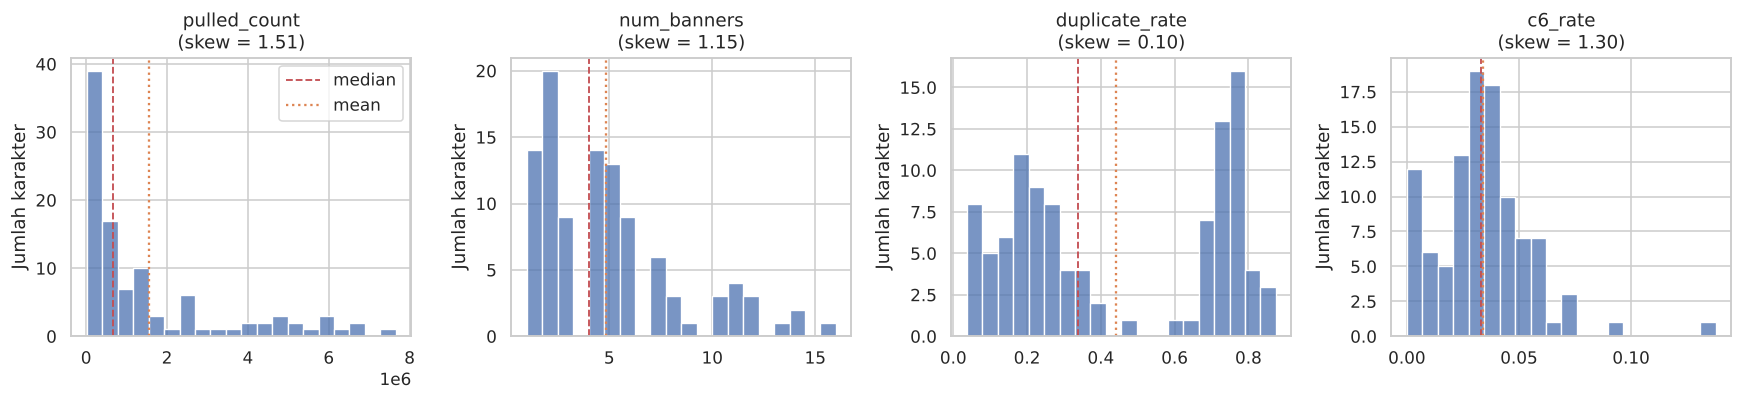

In [2]:
KOLOM_NUM = ['pulled_count', 'num_banners', 'duplicate_rate', 'c6_rate']
ringkas = pd.DataFrame({
    'n (setelah dropna)': [df[c].dropna().shape[0] for c in KOLOM_NUM],
    'mean': df[KOLOM_NUM].mean().values, 'median': df[KOLOM_NUM].median().values,
    'std': df[KOLOM_NUM].std().values, 'min': df[KOLOM_NUM].min().values,
    'max': df[KOLOM_NUM].max().values, 'skewness': df[KOLOM_NUM].skew().values,
}, index=KOLOM_NUM)
display(ringkas.round(3))

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, kol in zip(ax, KOLOM_NUM):
    sns.histplot(df[kol], bins=20, ax=a, color='#4C72B0')
    a.axvline(df[kol].median(), color='#C44E52', ls='--', lw=1.2, label='median')
    a.axvline(df[kol].mean(), color='#DD8452', ls=':', lw=1.5, label='mean')
    a.set(title=f'{kol}\n(skew = {df[kol].skew():.2f})', xlabel='', ylabel='Jumlah karakter')
ax[0].legend()
plt.tight_layout(); plt.savefig(FIG + '/m3_univariat_numerik.png', bbox_inches='tight'); plt.show()

In [3]:
# duplicate_rate tampak dua puncak: apakah terkait rarity?
print(df.groupby('bintang', observed=True)['duplicate_rate'].agg(['count', 'min', 'median', 'max']).round(3).to_string(), '\n')

# avg_copies_per_player tidak dianalisis terpisah: apakah ia turunan dari duplicate_rate?
selisih = (df['avg_copies_per_player'] - 1 / (1 - df['duplicate_rate'])).abs().max()
print(f'avg_copies_per_player vs 1/(1 - duplicate_rate): selisih maksimum = {selisih:.2e}')
print('Spearman duplicate_rate ~ avg_copies_per_player =', round(stats.spearmanr(df['duplicate_rate'], df['avg_copies_per_player'])[0], 2))

         count    min  median    max
bintang                             
4★          45  0.595   0.749  0.875
5★          58  0.037   0.202  0.459 

avg_copies_per_player vs 1/(1 - duplicate_rate): selisih maksimum = 1.46e-09
Spearman duplicate_rate ~ avg_copies_per_player = 1.0


**Tafsiran.**
- **Miring ke kanan:** `pulled_count` (skewness 1,51; median 652 ribu jauh di bawah rata-rata 1,56 juta), `c6_rate` (1,30), dan `num_banners` (1,15; median 4 banner, rentang 1–16).
  Rata-rata ditarik ke atas oleh sebagian kecil karakter, sehingga median dan ukuran berbasis peringkat (Spearman) lebih cocok.
- **`duplicate_rate` dua puncak:** skewness hanya 0,10, padahal histogramnya terbelah dua gugus. **Skewness tidak mendeteksi jumlah puncak**, dan rata-rata (0,44) jatuh di lembah di antara dua gugus sehingga tidak mewakili karakter mana pun.
  Penyebabnya `rarity`: seluruh 45 karakter bintang 4 punya `duplicate_rate` 0,60–0,87 dan seluruh 58 bintang 5 punya 0,04–0,46, terpisah sempurna. Variabel ini harus dibaca **per kelompok rarity**.
- **`c6_rate`:** satu karakter bernilai sekitar 0,14, hampir satu setengah kali nilai tertinggi berikutnya (0,09; lalu 0,07). Ia tidak mustahil (rentang 0–1 lolos), jadi dibiarkan dan dicatat.
- **`avg_copies_per_player`** adalah turunan dari `duplicate_rate` (selisih terhadap 1/(1−`duplicate_rate`) di bawah 1e-8 dan Spearman 1,00), sehingga tidak dianalisis terpisah agar tidak dihitung sebagai dua bukti.

## 2. Fokus P1: sebaran `pulled_count`

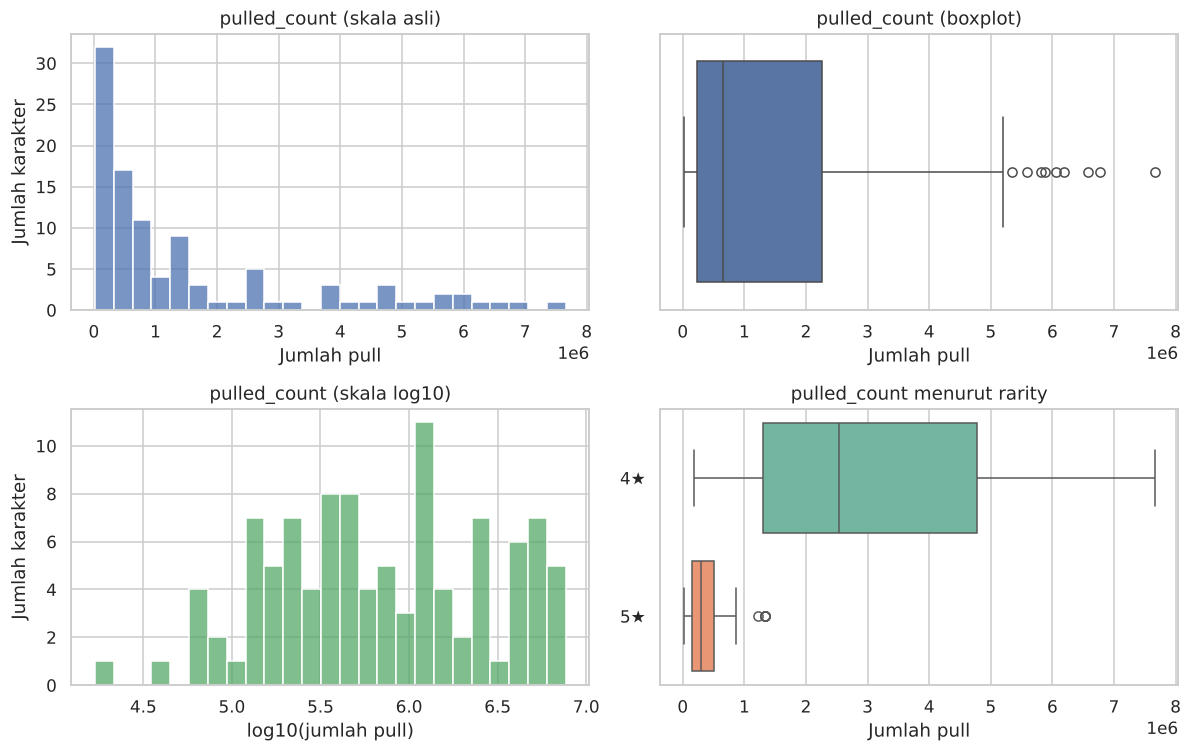

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(df['pulled_count'], bins=25, ax=ax[0, 0], color='#4C72B0')
ax[0, 0].set(title='pulled_count (skala asli)', xlabel='Jumlah pull', ylabel='Jumlah karakter')
sns.boxplot(x=df['pulled_count'], ax=ax[0, 1], color='#4C72B0')
ax[0, 1].set(title='pulled_count (boxplot)', xlabel='Jumlah pull')
sns.histplot(np.log10(df['pulled_count']), bins=25, ax=ax[1, 0], color='#55A868')
ax[1, 0].set(title='pulled_count (skala log10)', xlabel='log10(jumlah pull)', ylabel='Jumlah karakter')
sns.boxplot(data=df, x='pulled_count', y='bintang', hue='bintang', legend=False, ax=ax[1, 1], palette='Set2', order=['4★', '5★'])
ax[1, 1].set(title='pulled_count menurut rarity', xlabel='Jumlah pull', ylabel='')
plt.tight_layout(); plt.savefig(FIG + '/m3_univariat_pulled_count.png', bbox_inches='tight'); plt.show()

In [5]:
# Outlier: aturan IQR dihitung dua cara (seluruh data vs per kelompok rarity)
def iqr_batas(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

lo, hi = iqr_batas(df['pulled_count'])
print(f'Seluruh data  : batas atas = {hi:,.0f} -> {int((df.pulled_count > hi).sum())} karakter di atas batas')
print('  rinciannya   :', df.loc[df.pulled_count > hi, 'bintang'].value_counts().to_dict(), '\n')
for r, s in df.groupby('bintang', observed=True):
    lo, hi = iqr_batas(s['pulled_count'])
    print(f'Per kelompok {r}: batas atas = {hi:>12,.0f} -> {int((s.pulled_count > hi).sum())} karakter di atas batas (n={len(s)})')
print()
print(df.groupby('bintang', observed=True)['pulled_count'].median().rename('median pulled_count').to_frame().T.to_string(), '\n')
print('Baris pulled_tidak_cocok menurut rarity:', df.loc[df.pulled_tidak_cocok, 'bintang'].value_counts().to_dict(), '\n')
print(df.nlargest(5, 'pulled_count')[['name', 'bintang', 'standar', 'num_banners', 'pulled_count']].to_string(index=False))

Seluruh data  : batas atas = 5,316,779 -> 9 karakter di atas batas
  rinciannya   : {'4★': 9} 

Per kelompok 4★: batas atas =    9,976,347 -> 0 karakter di atas batas (n=45)
Per kelompok 5★: batas atas =    1,047,021 -> 6 karakter di atas batas (n=58)

bintang                     4★        5★
median pulled_count  2542518.0  288172.0 

Baris pulled_tidak_cocok menurut rarity: {'4★': 7, '5★': 2} 

        name bintang        standar  num_banners  pulled_count
b8e1834cf4dd      4★ Banner standar           16       7659164
34a469f17a8f      4★ Banner standar           12       6776259
f3badd462d7a      4★ Banner standar           11       6574926
b3f100226818      4★ Banner standar           14       6183960
fa1666fa5c45      4★ Banner standar           12       6055321


**Tafsiran (P1).**
Jumlah *pull* sangat miring ke kanan (skewness 1,51); histogram skala log jauh lebih simetris. Boxplot menandai **9 karakter di atas batas IQR, semuanya bintang 4**.
Tetapi bila batas dihitung **di dalam tiap kelompok rarity**, tidak ada satu pun bintang 4 yang menjadi outlier: mereka bukan anomali, melainkan kelompok yang memang berbeda
(median bintang 4 ≈ 2,54 juta, sekitar sembilan kali median bintang 5 ≈ 288 ribu). Di dalam bintang 5 justru 6 karakter melewati batas kelompoknya: ekor kanan yang wajar secara angka (tidak ada nilai mustahil), dan dicatat saja.
Lima karakter dengan *pull* tertinggi semuanya bintang 4; nama asli tidak bisa disebut karena `name` sudah di-hash.
Sembilan baris `pulled_tidak_cocok` **tujuh di antaranya bintang 4**, yaitu kelompok ber-*pull* tinggi; ini penting saat membaca uji sensitivitas di notebook 04.
**Keputusan:** tidak ada baris yang dibuang; `rarity` dipakai sebagai pembeda di notebook 04.

## 3. Variabel kategorikal

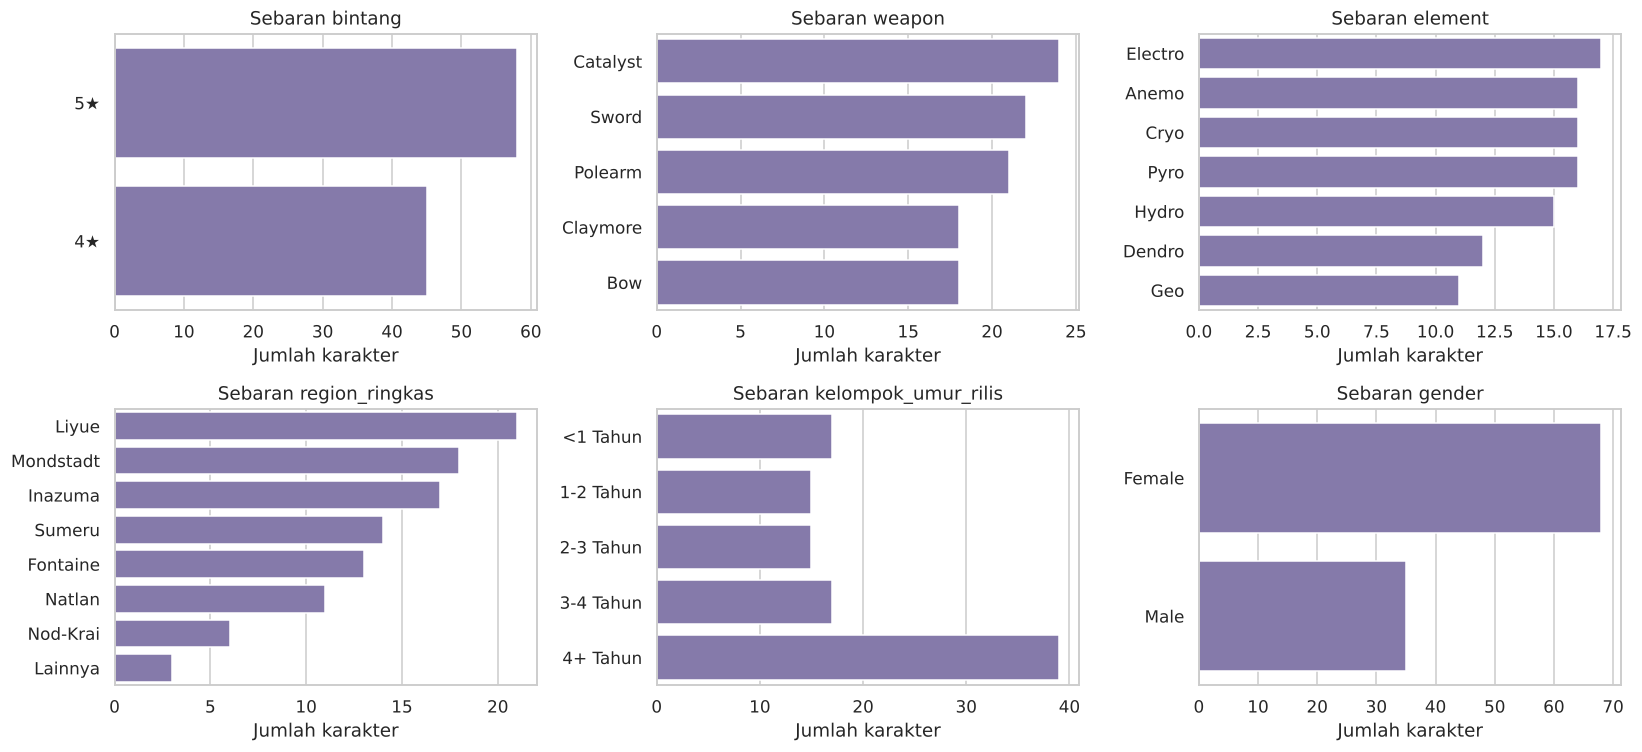

region
Liyue                 21
Mondstadt             18
Inazuma               17
Sumeru                14
Fontaine              13
Natlan                11
Nod-Krai               6
Snezhnaya              2
Extra-Terresterial     1 

standar
Banner standar          53
Bukan banner standar    50


In [6]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
rencana = [('bintang', None), ('weapon', None), ('element', None),
           ('region_ringkas', None), ('kelompok_umur_rilis', URUT_USIA), ('gender', None)]
for a, (kol, urut) in zip(ax.flat, rencana):
    urut = urut if urut is not None else df[kol].value_counts().index
    sns.countplot(data=df, y=kol, order=urut, ax=a, color='#8172B2')
    a.set(title=f'Sebaran {kol}', xlabel='Jumlah karakter', ylabel='')
plt.tight_layout(); plt.savefig(FIG + '/m3_univariat_kategorikal.png', bbox_inches='tight'); plt.show()
print(df['region'].value_counts().to_string(), '\n')
print(df['standar'].value_counts().to_string())

**Tafsiran.** Bintang 5 (58) lebih banyak daripada bintang 4 (45); banner standar 53 karakter, bukan standar 50. Senjata dan elemen cukup merata (kategori terbesar: Catalyst 23%, Electro 17%).
**Usia rilis:** kelompok "4+ Tahun" terbesar (39 karakter, 38%), sedangkan empat kelompok lain 15–17 karakter, sehingga kelompok tertua jauh lebih padat.
**Region:** Liyue (21) dan Mondstadt (18) terbesar; Snezhnaya (2) dan Extra-Terresterial (1) terlalu kecil sehingga digabung menjadi "Lainnya" (3 karakter) hanya untuk analisis; ejaan `Extra-Terresterial` di `region` tidak diubah.
**Gender** (diturunkan dari `3D-model`) tidak seimbang: 68 perempuan dan 35 laki-laki; perbandingan antar gender perlu hati-hati karena kelompoknya tidak setara.

## 4. Ringkasan univariat

| Variabel | Bentuk | Catatan |
|---|---|---|
| `pulled_count` | Sangat miring ke kanan | Gunakan Spearman atau skala log; bintang 4 adalah kelompok berbeda, bukan outlier |
| `num_banners`, `c6_rate` | Miring ke kanan | Median lebih mewakili daripada rata-rata |
| `duplicate_rate` | **Dua puncak**, skewness ≈ 0 menyesatkan | Terpisah sempurna menurut `rarity` (4★ ≥ 0,60; 5★ ≤ 0,46); baca per kelompok |
| `avg_copies_per_player` | Turunan `duplicate_rate` | Tidak dianalisis terpisah |
| `kelompok_umur_rilis` | Ordinal, kelompok 4+ Tahun terbesar (39) | Dikode 1–5; pakai Spearman, bukan Pearson |
| `region` | Kategori kecil (1–2 karakter) | Digabung menjadi "Lainnya" untuk analisis |

## 5. Daftar periksa
- [ ] Notebook berjalan dengan *Restart & Run All*, path relatif
- [ ] Semua variabel penting ditafsirkan (bukan hanya `describe()`)
- [ ] *n* yang dilaporkan adalah n setelah `dropna()`
- [ ] Data dibaca dari `data/processed/`, bukan `data/raw/`